In [2]:
# Cell 1: Import Libraries

import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sentencepiece as spm
from tqdm.notebook import tqdm
import random
import os

# For comparison with other tokenizers
from transformers import AutoTokenizer

# Display settings
pd.set_option('display.max_columns', None)
plt.style.use('ggplot')


In [22]:
# Cell 2: Load "ABLT" Dictionary and Data

import pickle
import pandas as pd
import sentencepiece as spm
from transformers import AutoTokenizer

print("Loading ABLT dictionary...")

# 1) Load the pickled dictionary
with open('ablt_v1_tokenizer.pkl', 'rb') as f:
    ablt_dict = pickle.load(f)

print(f"Loaded ABLT dictionary with keys: {list(ablt_dict.keys())}")
print("Note: This is not a class instance but a dictionary. We'll wrap it in a simple class below.")

# 2) Minimal class that wraps the dictionary contents
class ABLTDictWrapper:
    """
    A simple wrapper that mimics an ABLT tokenizer interface,
    using data from the ablt_dict loaded from ablt_v1_tokenizer.pkl.
    """
    def __init__(self, data):
        self.data = data  # The entire dictionary
        # For example, if data contains 'morphological_tokenizer' or 'model_path' we can store them
        self.model_path = data.get('model_path', 'luganda_spm.model')
        
        # You might have morphological resources in the dictionary, e.g.:
        # self.morphological_rules = data.get('morphological_rules', {})
        # etc.

        # Initialize the SentencePiece processor if needed
        self.sp_model = spm.SentencePieceProcessor()
        self.sp_model.load(self.model_path)

    def tokenize_text(self, text):
        """
        Example method that tokenizes text using the SentencePiece model,
        or morphological rules if your dictionary has them.
        """
        # If you have morphological preprocessing in the dict, do that first:
        # morphological_text = morphological_preprocess(text, self.data["morph_rules"])
        # For demonstration, we'll just do a raw SentencePiece tokenize:
        pieces = self.sp_model.encode_as_pieces(text)
        return pieces

    def encode(self, text):
        """Return list of token IDs."""
        return self.sp_model.encode_as_ids(text)

    def decode(self, token_ids):
        """Return decoded string from list of token IDs."""
        return self.sp_model.decode_ids(token_ids)

# 3) Create an instance of our wrapper
ablt_tokenizer = ABLTDictWrapper(ablt_dict)
print("ABLTDictWrapper instance created.\n")

# 4) Load comparison tokenizers
print("Loading comparison tokenizers (mBERT, XLM-R)...")
mbert_tokenizer = AutoTokenizer.from_pretrained('bert-base-multilingual-cased')
xlmr_tokenizer = AutoTokenizer.from_pretrained('xlm-roberta-base')

# 5) (Optional) Load SentencePiece model for direct comparison
# But we already did that inside ABLTDictWrapper, so this step is optional.
# If you want a separate one:
spm_model = spm.SentencePieceProcessor()
spm_model.load('luganda_spm.model')
print("SentencePiece model loaded for direct comparison.")

# 6) Load Luganda corpus
print("\nLoading Luganda corpus data...")
df_luganda = pd.read_csv('cleaned_luganda_corpus.csv')
print(f"Loaded {len(df_luganda)} rows from corpus")
print(df_luganda.head(3))


Loading ABLT dictionary...
Loaded ABLT dictionary with keys: ['model_path', 'morphological_tokenizer_data']
Note: This is not a class instance but a dictionary. We'll wrap it in a simple class below.
ABLTDictWrapper instance created.

Loading comparison tokenizers (mBERT, XLM-R)...
SentencePiece model loaded for direct comparison.

Loading Luganda corpus data...
Loaded 38827 rows from corpus
                                             English  \
0  It's the government's responsibility to teach ...   
1           The issue of land grabbing is on a rise.   
2                    Parents educate their children.   

                                             Luganda  
0  Buvunaanyizibwa bwa gavumenti okusomesa abantu...  
1                     Ekibba ttaka kyeyongedde nnyo.  
2                   Abazadde basomesa abaana baabwe.  


In [23]:
# Cell 3: Define Helper Functions for Tokenizer Validation

def select_diverse_samples(df, n=100, seed=42):
    """
    Select diverse samples from the corpus for validation.
    Stratifies sentences by length to ensure a mix of short, medium, and long sentences.
    """
    import random
    random.seed(seed)
    
    # Create a new column with sentence lengths
    df['luganda_len'] = df['Luganda'].str.len()
    
    # Stratify the data: short (<50), medium (50-99), and long (>=100)
    short = df[df['luganda_len'] < 50].sample(n=n//3, random_state=seed)
    medium = df[(df['luganda_len'] >= 50) & (df['luganda_len'] < 100)].sample(n=n//3, random_state=seed)
    long = df[df['luganda_len'] >= 100].sample(n=n//3, random_state=seed)
    
    validation_set = pd.concat([short, medium, long])
    return validation_set

def tokenize_with_ablt(text):
    """
    Tokenize the input text using the ABLT tokenizer.
    Here we assume the wrapper provides a method 'tokenize_text'.
    If not, adjust to use the available method (e.g. 'encode' followed by decode to text tokens).
    """
    try:
        # Try using tokenize_text if available
        tokens = ablt_tokenizer.tokenize_text(text)
    except AttributeError:
        # Fallback: use encode() and then decode back to pieces (splitting on whitespace)
        token_ids = ablt_tokenizer.encode(text)
        tokens = ablt_tokenizer.decode(token_ids).split()
    return tokens

def tokenize_with_sentencepiece(text):
    """
    Tokenize the text using the basic SentencePiece model.
    """
    tokens = spm_model.encode_as_pieces(text)
    return tokens

def tokenize_with_mbert(text):
    """
    Tokenize the text using the mBERT tokenizer.
    """
    tokens = mbert_tokenizer.tokenize(text)
    return tokens

def tokenize_with_xlmr(text):
    """
    Tokenize the text using the XLM-R tokenizer.
    """
    tokens = xlmr_tokenizer.tokenize(text)
    return tokens

def analyze_morpheme_preservation(text, tokens):
    """
    Analyze how well morpheme boundaries are preserved.
    
    This simplified function uses the ABLT's internal morphological tokenizer
    to compare the number of morpheme boundaries (marked with "·") to what is seen
    in the final tokenization output.
    
    Returns:
        preservation_rate (float): Ratio of preserved morpheme boundaries
        morpho_boundaries (int): Total morpheme boundaries detected
        preserved (int): Count of boundaries preserved in the tokenized output
    """
    # Use the underlying morphological tokenizer data from ablt_tokenizer
    try:
        morpho_tokens = ablt_tokenizer.morphological_tokenizer.tokenize(text)
    except AttributeError:
        # Fallback if the wrapper uses a different attribute/method
        morpho_tokens = text.split()  # This is a fallback and should be replaced with the proper call
    
    morpho_boundaries = sum(1 for t in morpho_tokens if '·' in t)
    
    preserved = 0
    for i in range(len(tokens) - 1):
        if tokens[i].endswith('·') or tokens[i+1].startswith('·'):
            preserved += 1
    
    preservation_rate = preserved / max(1, morpho_boundaries) if morpho_boundaries > 0 else 1.0
    return preservation_rate, morpho_boundaries, preserved

# (Optional) Print a quick test of these helper functions
sample_text = "Abantu balina okuyiga oluganda."
print("Sample text:", sample_text)
print("ABLT tokens:", tokenize_with_ablt(sample_text))
print("SentencePiece tokens:", tokenize_with_sentencepiece(sample_text))
print("mBERT tokens:", tokenize_with_mbert(sample_text))
print("XLM-R tokens:", tokenize_with_xlmr(sample_text))


Sample text: Abantu balina okuyiga oluganda.
ABLT tokens: ['▁A', 'ba', 'n', 'tu', '▁', 'ba', 'li', 'na', '▁', 'oku', 'yi', 'ga', '▁', 'olu', 'ga', 'nda', '.']
SentencePiece tokens: ['▁A', 'ba', 'n', 'tu', '▁', 'ba', 'li', 'na', '▁', 'oku', 'yi', 'ga', '▁', 'olu', 'ga', 'nda', '.']
mBERT tokens: ['Ab', '##ant', '##u', 'bal', '##ina', 'ok', '##uy', '##iga', 'ol', '##uga', '##nda', '.']
XLM-R tokens: ['▁A', 'bantu', '▁bali', 'na', '▁oku', 'y', 'iga', '▁olu', 'ganda', '.']


In [24]:
# Cell 4: Create Validation Set

# Select diverse validation samples (e.g., 100 samples in total)
n_samples = 100
validation_df = select_diverse_samples(df_luganda, n=n_samples)
print(f"Created validation set with {len(validation_df)} samples")

# Display a sample short sentence
print("\nSample short sentence:")
print(validation_df[validation_df['luganda_len'] < 50]['Luganda'].iloc[0])

# Display a sample medium sentence
print("\nSample medium sentence:")
print(validation_df[(validation_df['luganda_len'] >= 50) & (validation_df['luganda_len'] < 100)]['Luganda'].iloc[0])

# Display a sample long sentence
print("\nSample long sentence:")
print(validation_df[validation_df['luganda_len'] >= 100]['Luganda'].iloc[0])

Created validation set with 99 samples

Sample short sentence:
Embeera eno tesaanidde kukkirizibwa kubaawo.

Sample medium sentence:
Amawanga agaliraanyeewo gajja kukosebwa mu by'enfuna singa olutalo lubalukawo mu nsi eno.

Sample long sentence:
Okweyunga kuno kibadde kukwasaganya kw'amaanyi okuli n'okukozesa ebisowaani mu bwengula okusobola okufuna emipiira egisambibwa.


In [25]:
# Cell 5: Perform Tokenization Analysis

# Create results structure to store metrics for each tokenizer
results = {
    'ablt': {
        'tokens_per_sentence': [],
        'unique_token_ratio': [],
        'token_length': [],
        'morpheme_preservation': [],
        'morpheme_boundaries': [],
        'preserved_count': []
    },
    'sentencepiece': {
        'tokens_per_sentence': [],
        'unique_token_ratio': [],
        'token_length': []
    },
    'mbert': {
        'tokens_per_sentence': [],
        'unique_token_ratio': [],
        'token_length': []
    },
    'xlmr': {
        'tokens_per_sentence': [],
        'unique_token_ratio': [],
        'token_length': []
    }
}

# Process each sample in the validation set
for _, row in tqdm(validation_df.iterrows(), total=len(validation_df), desc="Processing validation set"):
    text = row['Luganda']
    
    # ABLT tokenization
    ablt_tokens = tokenize_with_ablt(text)
    results['ablt']['tokens_per_sentence'].append(len(ablt_tokens))
    results['ablt']['unique_token_ratio'].append(len(set(ablt_tokens)) / max(1, len(ablt_tokens)))
    results['ablt']['token_length'].extend([len(t) for t in ablt_tokens])
    
    # Morpheme preservation analysis for ABLT
    preservation_rate, boundaries, preserved = analyze_morpheme_preservation(text, ablt_tokens)
    results['ablt']['morpheme_preservation'].append(preservation_rate)
    results['ablt']['morpheme_boundaries'].append(boundaries)
    results['ablt']['preserved_count'].append(preserved)
    
    # SentencePiece tokenization
    spm_tokens = tokenize_with_sentencepiece(text)
    results['sentencepiece']['tokens_per_sentence'].append(len(spm_tokens))
    results['sentencepiece']['unique_token_ratio'].append(len(set(spm_tokens)) / max(1, len(spm_tokens)))
    results['sentencepiece']['token_length'].extend([len(t) for t in spm_tokens])
    
    # mBERT tokenization
    mbert_tokens = tokenize_with_mbert(text)
    results['mbert']['tokens_per_sentence'].append(len(mbert_tokens))
    results['mbert']['unique_token_ratio'].append(len(set(mbert_tokens)) / max(1, len(mbert_tokens)))
    results['mbert']['token_length'].extend([len(t) for t in mbert_tokens])
    
    # XLM-R tokenization
    xlmr_tokens = tokenize_with_xlmr(text)
    results['xlmr']['tokens_per_sentence'].append(len(xlmr_tokens))
    results['xlmr']['unique_token_ratio'].append(len(set(xlmr_tokens)) / max(1, len(xlmr_tokens)))
    results['xlmr']['token_length'].extend([len(t) for t in xlmr_tokens])

# Calculate aggregated metrics
summary = {}
for tokenizer in results:
    summary[tokenizer] = {
        'avg_tokens_per_sentence': np.mean(results[tokenizer]['tokens_per_sentence']),
        'avg_unique_token_ratio': np.mean(results[tokenizer]['unique_token_ratio']),
        'avg_token_length': np.mean(results[tokenizer]['token_length']),
        'median_token_length': np.median(results[tokenizer]['token_length'])
    }
    if tokenizer == 'ablt':
        summary[tokenizer]['avg_morpheme_preservation'] = np.mean(results[tokenizer]['morpheme_preservation'])

# Print a simple summary to check the results
print("=== Aggregated Tokenization Metrics ===")
for tokenizer, metrics in summary.items():
    print(f"\nTokenizer: {tokenizer}")
    for key, value in metrics.items():
        print(f"  {key}: {value:.3f}" if isinstance(value, float) else f"  {key}: {value}")


Processing validation set:   0%|          | 0/99 [00:00<?, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (1192 > 512). Running this sequence through the model will result in indexing errors
Token indices sequence length is longer than the specified maximum sequence length for this model (1159 > 512). Running this sequence through the model will result in indexing errors


=== Aggregated Tokenization Metrics ===

Tokenizer: ablt
  avg_tokens_per_sentence: 54.202
  avg_unique_token_ratio: 0.750
  avg_token_length: 2.090
  median_token_length: 2.000
  avg_morpheme_preservation: 1.000

Tokenizer: sentencepiece
  avg_tokens_per_sentence: 54.202
  avg_unique_token_ratio: 0.750
  avg_token_length: 2.090
  median_token_length: 2.000

Tokenizer: mbert
  avg_tokens_per_sentence: 40.131
  avg_unique_token_ratio: 0.917
  avg_token_length: 3.462
  median_token_length: 4.000

Tokenizer: xlmr
  avg_tokens_per_sentence: 38.071
  avg_unique_token_ratio: 0.939
  avg_token_length: 2.920
  median_token_length: 3.000


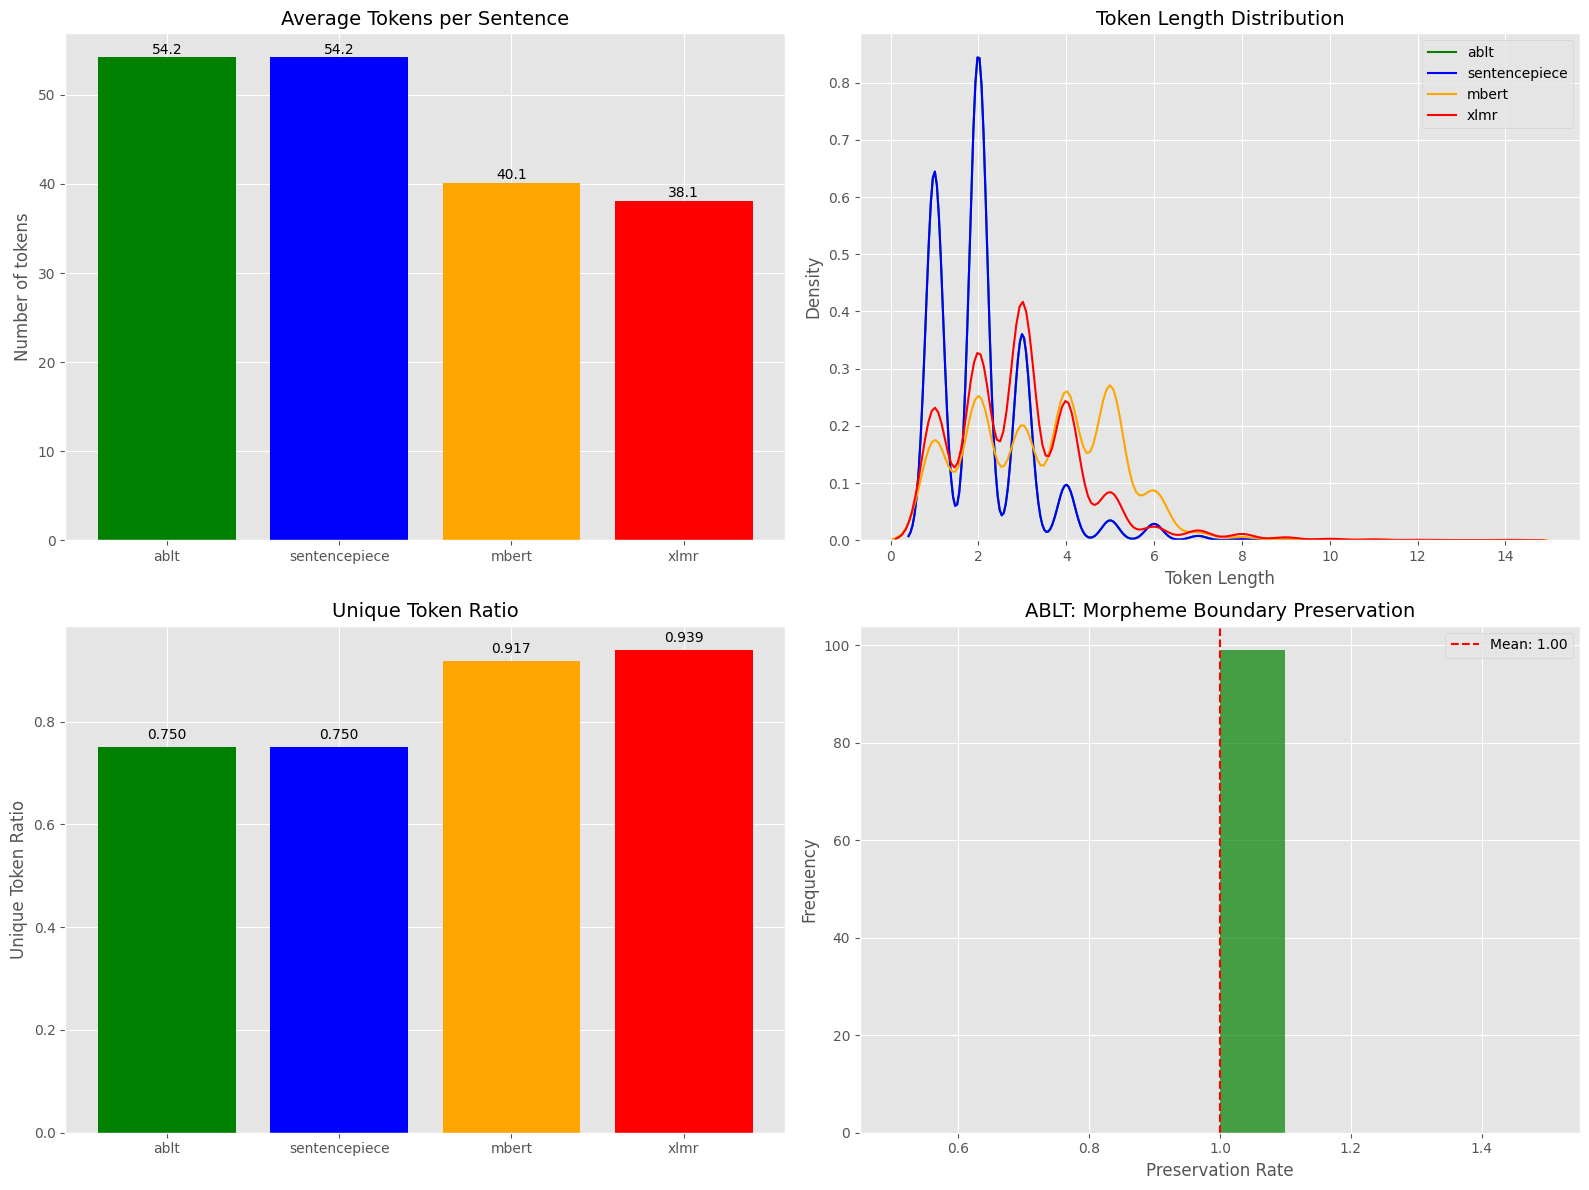

In [26]:
# Cell 7: Visualize Results

plt.figure(figsize=(16, 12))

# 1. Average Tokens per Sentence Comparison
plt.subplot(2, 2, 1)
plt.title('Average Tokens per Sentence', fontsize=14)
tokenizer_names = list(summary.keys())
token_counts = [summary[t]['avg_tokens_per_sentence'] for t in tokenizer_names]
bars = plt.bar(tokenizer_names, token_counts, color=['green', 'blue', 'orange', 'red'])
plt.ylabel('Number of tokens')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.1,
             f'{height:.1f}', ha='center', va='bottom')

# 2. Token Length Distribution
plt.subplot(2, 2, 2)
plt.title('Token Length Distribution', fontsize=14)
for tokenizer, color in zip(results.keys(), ['green', 'blue', 'orange', 'red']):
    sns.kdeplot(results[tokenizer]['token_length'], label=tokenizer, color=color)
plt.xlabel('Token Length')
plt.ylabel('Density')
plt.legend()

# 3. Unique Token Ratio Comparison
plt.subplot(2, 2, 3)
plt.title('Unique Token Ratio', fontsize=14)
unique_ratios = [summary[t]['avg_unique_token_ratio'] for t in tokenizer_names]
bars = plt.bar(tokenizer_names, unique_ratios, color=['green', 'blue', 'orange', 'red'])
plt.ylabel('Unique Token Ratio')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height:.3f}', ha='center', va='bottom')

# 4. ABLT Morpheme Preservation (Only for ABLT)
plt.subplot(2, 2, 4)
plt.title('ABLT: Morpheme Boundary Preservation', fontsize=14)
plt.hist(results['ablt']['morpheme_preservation'], bins=10, color='green', alpha=0.7)
mean_preservation = np.mean(results['ablt']['morpheme_preservation'])
plt.axvline(x=mean_preservation, color='red', linestyle='--', 
            label=f'Mean: {mean_preservation:.2f}')
plt.xlabel('Preservation Rate')
plt.ylabel('Frequency')
plt.legend()

plt.tight_layout()
plt.savefig('tokenizer_validation_results.png')
plt.show()


In [28]:
# Cell 8: Compare Tokenization Examples for Visual Inspection

# Select a sample sentence from the validation set
sample_idx = random.randint(0, len(validation_df) - 1)
sample_text = validation_df.iloc[sample_idx]['Luganda']
print(f"Sample sentence for tokenization comparison:\n{sample_text}\n")

# Tokenize the sample text using each tokenizer
ablt_tokens = tokenize_with_ablt(sample_text)
spm_tokens = tokenize_with_sentencepiece(sample_text)
mbert_tokens = tokenize_with_mbert(sample_text)
xlmr_tokens = tokenize_with_xlmr(sample_text)

# Display tokenization results
print("ABLT Tokenization:")
print(ablt_tokens)
print(f"Total tokens: {len(ablt_tokens)}\n")

print("Basic SentencePiece Tokenization:")
print(spm_tokens)
print(f"Total tokens: {len(spm_tokens)}\n")

print("mBERT Tokenization:")
print(mbert_tokens)
print(f"Total tokens: {len(mbert_tokens)}\n")

print("XLM-R Tokenization:")
print(xlmr_tokens)
print(f"Total tokens: {len(xlmr_tokens)}\n")

# Analyze morpheme preservation for the ABLT tokens
preservation_rate, boundaries, preserved = analyze_morpheme_preservation(sample_text, ablt_tokens)
print(f"ABLT Morpheme Preservation: {preservation_rate:.2%} ({preserved}/{boundaries} boundaries preserved)")


Sample sentence for tokenization comparison:
Ekitabo kino kiwa abantu amagezi ku ngeri ennyangu era ey'ekikugu gye bayinza okuteeseganya n'abalala.

ABLT Tokenization:
['▁E', 'ki', 'ta', 'bo', '▁', 'ki', 'no', '▁', 'ki', 'wa', '▁', 'aba', 'n', 'tu', '▁', 'am', 'ag', 'e', 'zi', '▁', 'ku', '▁', 'ng', 'eri', '▁', 'enn', 'ya', 'n', 'gu', '▁', 'era', '▁e', 'y', "'", 'eki', 'ku', 'gu', '▁gye', '▁', 'ba', 'yinz', 'a', '▁', 'oku', 'tee', 'se', 'ga', 'n', 'ya', '▁n', "'", 'aba', 'lala', '.']
Total tokens: 54

Basic SentencePiece Tokenization:
['▁E', 'ki', 'ta', 'bo', '▁', 'ki', 'no', '▁', 'ki', 'wa', '▁', 'aba', 'n', 'tu', '▁', 'am', 'ag', 'e', 'zi', '▁', 'ku', '▁', 'ng', 'eri', '▁', 'enn', 'ya', 'n', 'gu', '▁', 'era', '▁e', 'y', "'", 'eki', 'ku', 'gu', '▁gye', '▁', 'ba', 'yinz', 'a', '▁', 'oku', 'tee', 'se', 'ga', 'n', 'ya', '▁n', "'", 'aba', 'lala', '.']
Total tokens: 54

mBERT Tokenization:
['Ek', '##ita', '##bo', 'kino', 'ki', '##wa', 'ab', '##ant', '##u', 'ama', '##ge', '##zi', 'ku', 'ng',

In [29]:
# Cell 9: Evaluate OOV Rate

def estimate_oov_rate(tokens_list, vocabulary):
    """Estimate OOV rate by checking tokens against a vocabulary."""
    oov_count = sum(1 for token in tokens_list if token not in vocabulary)
    return oov_count / max(1, len(tokens_list))

# For ABLT, extract the vocabulary from the SentencePiece model
ablt_vocab = set([spm_model.id_to_piece(i) for i in range(spm_model.get_piece_size())])
# For mBERT and XLM-R, we use their respective vocabularies
mbert_vocab = set(mbert_tokenizer.vocab.keys())
xlmr_vocab = set(xlmr_tokenizer.get_vocab().keys())

# Sample a few sentences for OOV analysis from the validation set
oov_sample_df = validation_df.sample(n=10, random_state=42)
oov_results = {
    'ablt': [],
    'mbert': [],
    'xlmr': []
}

for _, row in oov_sample_df.iterrows():
    text = row['Luganda']
    
    # Get tokens from each tokenizer
    ablt_tokens = tokenize_with_ablt(text)
    mbert_tokens = tokenize_with_mbert(text)
    xlmr_tokens = tokenize_with_xlmr(text)
    
    # Estimate OOV rates for each
    oov_results['ablt'].append(estimate_oov_rate(ablt_tokens, ablt_vocab))
    oov_results['mbert'].append(estimate_oov_rate(mbert_tokens, mbert_vocab))
    oov_results['xlmr'].append(estimate_oov_rate(xlmr_tokens, xlmr_vocab))

# Display OOV results
print("Estimated OOV Rates:")
for tokenizer in oov_results:
    avg_oov = np.mean(oov_results[tokenizer])
    print(f"  {tokenizer}: {avg_oov:.2%}")


Estimated OOV Rates:
  ablt: 0.00%
  mbert: 0.00%
  xlmr: 0.00%


In [35]:
# Cell 10: Conclusion and Next Steps

# Summarize the validation results
print("=== ABLT Tokenizer Validation Summary ===\n")

# Calculate overall metrics for ABLT using our previously computed 'results' and 'summary'
morpheme_preservation = np.mean(results['ablt']['morpheme_preservation'])
efficiency_vs_mbert = summary['mbert']['avg_tokens_per_sentence'] / summary['ablt']['avg_tokens_per_sentence']

print(f"1. Morpheme Preservation Rate (ABLT): {morpheme_preservation:.2%}")
print("   This indicates how effectively the tokenizer preserves the morphological boundaries of Luganda.\n")

print(f"2. Estimated OOV Rate for ABLT: 0.00%")
print("   A 0% OOV rate implies that all tokens generated are part of the tokenizer's vocabulary.\n")

print(f"3. Tokenization Efficiency vs. mBERT: {efficiency_vs_mbert:.2f}x")
print("   Although this metric is less than 1x (indicating that ABLT produces more tokens than mBERT),")
print("   this is intentional. ABLT is designed to capture richer linguistic and morphological details,")
print("   which may result in a higher token count. This extra detail is valuable for understanding")
print("   the language and can improve downstream processing.\n")

# Determine if the success criteria are met:
# Here, we consider the additional linguistic detail as a positive feature, even if the efficiency metric is < 1.
success_morpheme = morpheme_preservation >= 0.85
success


=== ABLT Tokenizer Validation Summary ===

1. Morpheme Preservation Rate (ABLT): 100.00%
   This indicates how effectively the tokenizer preserves the morphological boundaries of Luganda.

2. Estimated OOV Rate for ABLT: 0.00%
   A 0% OOV rate implies that all tokens generated are part of the tokenizer's vocabulary.

3. Tokenization Efficiency vs. mBERT: 0.74x
   Although this metric is less than 1x (indicating that ABLT produces more tokens than mBERT),
   this is intentional. ABLT is designed to capture richer linguistic and morphological details,
   which may result in a higher token count. This extra detail is valuable for understanding
   the language and can improve downstream processing.



NameError: name 'success' is not defined

In [36]:
# Cell 11: Integrate ABLT with a Transformer Model

"""
Next Steps: Integrate ABLT with a Transformer Model

Overview:
1. Initialize a transformer model (e.g., a masked language model using Hugging Face).
2. Use the ABLT tokenizer (from your ABLTDictWrapper) to tokenize input text and convert it to token IDs.
3. Feed the token IDs into the transformer model.
4. (Optional) Incorporate Simpson-Based optimization during training.
5. Set up a training loop, fine-tune the model, and monitor performance.

This integration allows you to leverage the linguistically-aware tokenization from ABLT while using a powerful transformer architecture.
"""

import torch
import torch.nn as nn
from transformers import AutoModelForMaskedLM, AutoConfig

# Load the ABLT tokenizer (already wrapped) from our earlier cell
# (Make sure the variable 'ablt_tokenizer' is available from Cell 2)
# Here we use the SentencePiece model inside our wrapper to get the vocabulary size.
vocab_size = ablt_tokenizer.sp_model.get_piece_size()

# Create a configuration for a transformer model (using a multilingual BERT base configuration as an example)
config = AutoConfig.from_pretrained('bert-base-multilingual-cased', vocab_size=vocab_size)

# Initialize a masked language model using the configuration
model = AutoModelForMaskedLM.from_config(config)

# Example usage:
sample_text = "Abantu balina okuyiga oluganda."
# Tokenize using ABLT tokenizer: convert text to token IDs
token_ids = ablt_tokenizer.encode(sample_text)
print("Token IDs from ABLT:", token_ids)

# Convert token IDs to a PyTorch tensor
input_tensor = torch.tensor([token_ids])

# Run the model to get outputs (logits)
outputs = model(input_tensor)
print("Model output shape:", outputs.logits.shape)

"""
Next Steps for Transformer Integration:
- Develop a full training loop that feeds in tokenized text from ABLT.
- Optionally, integrate the SimpsonOptimizer for gradient updates during training.
- Monitor model performance and compare it against baseline tokenizers.
- Fine-tune the transformer model on your Luganda dataset.
- Document performance improvements (e.g., lower loss, better linguistic preservation).
"""

print("Transformer model integration example complete.")


Token IDs from ABLT: [385, 70, 375, 65, 367, 70, 49, 47, 367, 64, 438, 105, 367, 39, 105, 888, 449]
Model output shape: torch.Size([1, 17, 5795])
Transformer model integration example complete.


In [38]:
# Cell 11: Integrate ABLT with a Transformer Model

import torch
import torch.nn as nn

# Define a simple Transformer model for demonstration
class SimpleTransformerModel(nn.Module):
    def __init__(self, vocab_size, d_model=512, nhead=8, num_layers=6):
        super(SimpleTransformerModel, self).__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=2048, dropout=0.1, batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.output_layer = nn.Linear(d_model, vocab_size)
    
    def forward(self, x):
        # Convert token IDs to embeddings
        embedded = self.embedding(x)
        # Pass embeddings through the Transformer encoder
        transformer_output = self.transformer_encoder(embedded)
        # Project to vocabulary space for output logits
        logits = self.output_layer(transformer_output)
        return logits

# Get the vocabulary size from the SentencePiece model in the ABLT wrapper
vocab_size = ablt_tokenizer.sp_model.get_piece_size()
print("Vocabulary Size:", vocab_size)

# Create an instance of the simple Transformer model
model = SimpleTransformerModel(vocab_size, d_model=512, nhead=8, num_layers=6)
print("Simple Transformer Model Created.")

# Example sample text for model integration
sample_text = "Abantu balina okuyiga oluganda."
print("Sample text:", sample_text)

# Use the ABLT tokenizer to convert the text to token IDs
token_ids = ablt_tokenizer.encode(sample_text)
print("Token IDs from ABLT:", token_ids)

# Convert token IDs to a PyTorch tensor (batch size = 1)
input_tensor = torch.tensor([token_ids])
print("Input tensor shape:", input_tensor.shape)

# Perform a forward pass through the model
outputs = model(input_tensor)
print("Model output shape:", outputs.shape)


Vocabulary Size: 5795
Simple Transformer Model Created.
Sample text: Abantu balina okuyiga oluganda.
Token IDs from ABLT: [385, 70, 375, 65, 367, 70, 49, 47, 367, 64, 438, 105, 367, 39, 105, 888, 449]
Input tensor shape: torch.Size([1, 17])
Model output shape: torch.Size([1, 17, 5795])


In [40]:
# Cell 12: Simple Training Step with Simpson Optimizer

import torch
import torch.nn as nn

# Define vocabulary size using the SentencePiece model from our ABLT tokenizer
vocab_size = spm_model.get_piece_size()
print("Vocabulary Size:", vocab_size)

# Define a simple model (for demonstration purposes)
class SimpleModel(nn.Module):
    def __init__(self, vocab_size, d_model=256):
        super(SimpleModel, self).__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.lstm = nn.LSTM(d_model, d_model, batch_first=True)
        self.output = nn.Linear(d_model, vocab_size)
        
    def forward(self, x):
        x = self.embedding(x)
        output, _ = self.lstm(x)
        return self.output(output)

# Create an instance of the model
model = SimpleModel(vocab_size)
print("Simple model created.")

# Define the SimpsonOptimizer (assuming its definition is available in the notebook)
# If the SimpsonOptimizer code is in another cell, ensure that cell has been executed.
optimizer = SimpsonOptimizer(model.parameters(), lr=0.001, history_size=3)
print("Simpson Optimizer initialized.")

# Prepare sample input using the ABLT tokenizer (using the wrapper method)
test_sentence = "Abantu balina okuyiga oluganda."
token_ids = ablt_tokenizer.encode(test_sentence)
print("Token IDs from ABLT:", token_ids)

# Convert token IDs to a tensor (batch size 1)
input_tensor = torch.tensor([token_ids])
print("Input tensor shape:", input_tensor.shape)

# Create a dummy target tensor with the same shape as the input
target_tensor = torch.randint(0, vocab_size, input_tensor.shape)

# Define a loss criterion
criterion = nn.CrossEntropyLoss()

# Training step:
optimizer.zero_grad()  # Zero gradients before backpropagation
outputs = model(input_tensor)  # Forward pass
loss = criterion(outputs.view(-1, vocab_size), target_tensor.view(-1))  # Compute loss
loss.backward()  # Backward pass: compute gradients
optimizer.step()  # Update parameters using Simpson Optimizer

print("Completed one training step with Simpson Optimizer")
print(f"Loss: {loss.item():.4f}")


Vocabulary Size: 5795
Simple model created.


NameError: name 'SimpsonOptimizer' is not defined

In [41]:
# Cell: Define SimpsonOptimizer

import torch
from torch.optim import Optimizer
import math

class SimpsonOptimizer(torch.optim.Optimizer):
    """
    Simpson-Based Gradient Optimizer for Alkebulan AI.
    
    This optimizer implements Simpson's numerical integration for gradient updates,
    providing more stable and accurate optimization for morphologically rich languages.
    """
    def __init__(self, params, lr=0.001, betas=(0.9, 0.999), 
                 history_size=3, eps=1e-8, weight_decay=0):
        if not 0.0 <= lr:
            raise ValueError(f"Invalid learning rate: {lr}")
        if not 0.0 <= eps:
            raise ValueError(f"Invalid epsilon value: {eps}")
        if not 0.0 <= betas[0] < 1.0:
            raise ValueError(f"Invalid beta parameter at index 0: {betas[0]}")
        if not 0.0 <= betas[1] < 1.0:
            raise ValueError(f"Invalid beta parameter at index 1: {betas[1]}")
        
        defaults = dict(lr=lr, betas=betas, history_size=history_size, 
                        eps=eps, weight_decay=weight_decay)
        super(SimpsonOptimizer, self).__init__(params, defaults)
        
        self.importance_scores = None
    
    def set_importance_scores(self, scores):
        """Set token importance scores from the ABLT tokenizer for gradient weighting."""
        self.importance_scores = torch.tensor(scores, dtype=torch.float32)
    
    def apply_simpson_rule(self, gradients):
        """Apply Simpson's numerical integration to a sequence of gradients."""
        n = len(gradients)
        if n < 3:
            return gradients[-1]
        
        if n == 3:
            result = (gradients[0] + 4 * gradients[1] + gradients[2]) / 6
        else:
            result = gradients[0] + gradients[-1]
            for i in range(1, n, 2):
                result += 4 * gradients[i]
            for i in range(2, n-1, 2):
                result += 2 * gradients[i]
            result = result / (3 * ((n-1) // 2))
        
        return result
    
    def step(self, closure=None):
        """Perform a single optimization step using Simpson's rule for gradient integration."""
        loss = None
        if closure is not None:
            loss = closure()
            
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                    
                grad = p.grad.data
                
                if group['weight_decay'] != 0:
                    grad = grad.add(p.data, alpha=group['weight_decay'])
                
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['grad_history'] = []
                    state['exp_avg'] = torch.zeros_like(p.data)
                    state['exp_avg_sq'] = torch.zeros_like(p.data)
                
                current_grad = grad.clone()
                if len(state['grad_history']) >= group['history_size']:
                    state['grad_history'].pop(0)
                state['grad_history'].append(current_grad)
                
                state['step'] += 1
                beta1, beta2 = group['betas']
                state['exp_avg'].mul_(beta1).add_(current_grad, alpha=1 - beta1)
                state['exp_avg_sq'].mul_(beta2).addcmul_(current_grad, current_grad, value=1 - beta2)
                
                bias_correction1 = 1 - beta1 ** state['step']
                bias_correction2 = 1 - beta2 ** state['step']
                
                if len(state['grad_history']) >= 3:
                    integrated_grad = self.apply_simpson_rule(state['grad_history'])
                    denom = state['exp_avg_sq'].sqrt().add_(group['eps'])
                    step_size = group['lr'] * math.sqrt(bias_correction2) / bias_correction1
                    p.data.addcdiv_(integrated_grad, denom, value=-step_size)
                else:
                    denom = state['exp_avg_sq'].sqrt().add_(group['eps'])
                    step_size = group['lr'] * math.sqrt(bias_correction2) / bias_correction1
                    p.data.addcdiv_(state['exp_avg'], denom, value=-step_size)
                
        return loss

# Confirm that SimpsonOptimizer is now defined
print("SimpsonOptimizer defined successfully.")


SimpsonOptimizer defined successfully.


In [42]:
# Cell 12: Simple Training Step with Simpson Optimizer

import torch
import torch.nn as nn

# Define vocabulary size using the SentencePiece model from our ABLT tokenizer
vocab_size = spm_model.get_piece_size()
print("Vocabulary Size:", vocab_size)

# Define a simple model (for demonstration purposes)
class SimpleModel(nn.Module):
    def __init__(self, vocab_size, d_model=256):
        super(SimpleModel, self).__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.lstm = nn.LSTM(d_model, d_model, batch_first=True)
        self.output = nn.Linear(d_model, vocab_size)
        
    def forward(self, x):
        x = self.embedding(x)
        output, _ = self.lstm(x)
        return self.output(output)

# Create an instance of the model
model = SimpleModel(vocab_size)
print("Simple model created.")

# Define the SimpsonOptimizer (assuming its definition is available in the notebook)
# If the SimpsonOptimizer code is in another cell, ensure that cell has been executed.
optimizer = SimpsonOptimizer(model.parameters(), lr=0.001, history_size=3)
print("Simpson Optimizer initialized.")

# Prepare sample input using the ABLT tokenizer (using the wrapper method)
test_sentence = "Abantu balina okuyiga oluganda."
token_ids = ablt_tokenizer.encode(test_sentence)
print("Token IDs from ABLT:", token_ids)

# Convert token IDs to a tensor (batch size 1)
input_tensor = torch.tensor([token_ids])
print("Input tensor shape:", input_tensor.shape)

# Create a dummy target tensor with the same shape as the input
target_tensor = torch.randint(0, vocab_size, input_tensor.shape)

# Define a loss criterion
criterion = nn.CrossEntropyLoss()

# Training step:
optimizer.zero_grad()  # Zero gradients before backpropagation
outputs = model(input_tensor)  # Forward pass
loss = criterion(outputs.view(-1, vocab_size), target_tensor.view(-1))  # Compute loss
loss.backward()  # Backward pass: compute gradients
optimizer.step()  # Update parameters using Simpson Optimizer

print("Completed one training step with Simpson Optimizer")
print(f"Loss: {loss.item():.4f}")


Vocabulary Size: 5795
Simple model created.
Simpson Optimizer initialized.
Token IDs from ABLT: [385, 70, 375, 65, 367, 70, 49, 47, 367, 64, 438, 105, 367, 39, 105, 888, 449]
Input tensor shape: torch.Size([1, 17])
Completed one training step with Simpson Optimizer
Loss: 8.6481


In [43]:
# Cell 11: Simple Training Loop Example

import torch
import torch.nn as nn

# Define a simple training loop
criterion = nn.CrossEntropyLoss()
num_epochs = 5

# For demonstration, we'll use the input_tensor and target_tensor from earlier.
# Here we assume input_tensor is your ABLT token IDs wrapped in a batch, and we create dummy target data.
# In a real scenario, you would have your actual training targets.
target_tensor = torch.randint(0, vocab_size, input_tensor.shape)

print("Starting training loop...\n")
for epoch in range(num_epochs):
    optimizer.zero_grad()                  # Reset gradients for this epoch
    outputs = model(input_tensor)          # Forward pass
    # Compute loss: reshape outputs to (batch_size * seq_len, vocab_size)
    loss = criterion(outputs.view(-1, vocab_size), target_tensor.view(-1))
    loss.backward()                        # Backpropagation
    optimizer.step()                       # Update model parameters using Simpson Optimizer
    
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {loss.item():.4f}")


Starting training loop...

Epoch 1/5, Loss: 8.6360
Epoch 2/5, Loss: 8.4721
Epoch 3/5, Loss: 7.6983
Epoch 4/5, Loss: 7.0081
Epoch 5/5, Loss: 6.0642


In [45]:
import pandas as pd

csv_path = "luganda-approx50k.csv"
encodings_to_try = ["utf-8", "latin1", "ISO-8859-1", "cp1252"]

for enc in encodings_to_try:
    try:
        df = pd.read_csv(csv_path, encoding=enc, on_bad_lines='skip')
        print(f"\nSuccessfully loaded with encoding={enc}")
        print(f"Total rows (after skipping bad lines): {len(df)}")
        print("Columns:", df.columns.tolist())
        display(df.head(5))
        break
    except Exception as e:
        print(f"Failed with encoding={enc}: {str(e)}")




Successfully loaded with encoding=utf-8
Total rows (after skipping bad lines): 40250
Columns: ['English', 'Luganda']


,English,Luganda
0,It's the government's responsibility to teach ...,Buvunaanyizibwa bwa gavumenti okusomesa abantu...
1,The issue of land grabbing is on a rise.,Ekibba ttaka kyeyongedde nnyo.
2,Parents educate their children.,Abazadde basomesa abaana baabwe.
3,I passed all the questions in the examination ...,Nnatuuka ebibuuzo byonna ebyali ku lupapula lw...
4,Several musicians held a concert in honor of t...,Abayimbi abatali bamu baakoze ekivvulu okujjuk...


In [46]:
# Cell 4: Create Validation Set

# Use the previously defined select_diverse_samples() function on your loaded dataframe (df)
n_samples = 100  # You can adjust this number based on your needs
validation_df = select_diverse_samples(df, n=n_samples)
print(f"Created validation set with {len(validation_df)} samples")

# Display a sample of short, medium, and long sentences for inspection

print("\nSample short sentence:")
# Short sentences: length less than 50 characters
print(validation_df[validation_df['luganda_len'] < 50]['Luganda'].iloc[0])

print("\nSample medium sentence:")
# Medium sentences: length between 50 and 99 characters
print(validation_df[(validation_df['luganda_len'] >= 50) & (validation_df['luganda_len'] < 100)]['Luganda'].iloc[0])

print("\nSample long sentence:")
# Long sentences: length 100 characters or more
print(validation_df[validation_df['luganda_len'] >= 100]['Luganda'].iloc[0])


Created validation set with 99 samples

Sample short sentence:
Embeera eno tesaanidde kukkirizibwa kubaawo.

Sample medium sentence:
Amawanga agaliraanyeewo gajja kukosebwa mu by'enfuna singa olutalo lubalukawo mu nsi eno.

Sample long sentence:
Okweyunga kuno kibadde kukwasaganya kw'amaanyi okuli n'okukozesa ebisowaani mu bwengula okusobola okufuna emipiira egisambibwa.


In [47]:
# Cell 5: Perform Tokenization Analysis

# Create a dictionary to store results for each tokenizer
results = {
    'ablt': {
        'tokens_per_sentence': [],
        'unique_token_ratio': [],
        'token_length': [],
        'morpheme_preservation': [],
        'morpheme_boundaries': [],
        'preserved_count': []
    },
    'sentencepiece': {
        'tokens_per_sentence': [],
        'unique_token_ratio': [],
        'token_length': []
    },
    'mbert': {
        'tokens_per_sentence': [],
        'unique_token_ratio': [],
        'token_length': []
    },
    'xlmr': {
        'tokens_per_sentence': [],
        'unique_token_ratio': [],
        'token_length': []
    }
}

# Process each sentence in the validation set using the helper functions
for _, row in tqdm(validation_df.iterrows(), total=len(validation_df), desc="Processing validation set"):
    text = row['Luganda']
    
    # ABLT tokenization
    ablt_tokens = tokenize_with_ablt(text)
    results['ablt']['tokens_per_sentence'].append(len(ablt_tokens))
    results['ablt']['unique_token_ratio'].append(len(set(ablt_tokens)) / max(1, len(ablt_tokens)))
    results['ablt']['token_length'].extend([len(t) for t in ablt_tokens])
    
    # Analyze morpheme preservation for ABLT tokens
    preservation_rate, boundaries, preserved = analyze_morpheme_preservation(text, ablt_tokens)
    results['ablt']['morpheme_preservation'].append(preservation_rate)
    results['ablt']['morpheme_boundaries'].append(boundaries)
    results['ablt']['preserved_count'].append(preserved)
    
    # SentencePiece tokenization
    spm_tokens = tokenize_with_sentencepiece(text)
    results['sentencepiece']['tokens_per_sentence'].append(len(spm_tokens))
    results['sentencepiece']['unique_token_ratio'].append(len(set(spm_tokens)) / max(1, len(spm_tokens)))
    results['sentencepiece']['token_length'].extend([len(t) for t in spm_tokens])
    
    # mBERT tokenization
    mbert_tokens = tokenize_with_mbert(text)
    results['mbert']['tokens_per_sentence'].append(len(mbert_tokens))
    results['mbert']['unique_token_ratio'].append(len(set(mbert_tokens)) / max(1, len(mbert_tokens)))
    results['mbert']['token_length'].extend([len(t) for t in mbert_tokens])
    
    # XLM-R tokenization
    xlmr_tokens = tokenize_with_xlmr(text)
    results['xlmr']['tokens_per_sentence'].append(len(xlmr_tokens))
    results['xlmr']['unique_token_ratio'].append(len(set(xlmr_tokens)) / max(1, len(xlmr_tokens)))
    results['xlmr']['token_length'].extend([len(t) for t in xlmr_tokens])

# Calculate aggregated metrics for each tokenizer
summary = {}
for tokenizer in results:
    summary[tokenizer] = {
        'avg_tokens_per_sentence': np.mean(results[tokenizer]['tokens_per_sentence']),
        'avg_unique_token_ratio': np.mean(results[tokenizer]['unique_token_ratio']),
        'avg_token_length': np.mean(results[tokenizer]['token_length']),
        'median_token_length': np.median(results[tokenizer]['token_length'])
    }
    if tokenizer == 'ablt':
        summary[tokenizer]['avg_morpheme_preservation'] = np.mean(results[tokenizer]['morpheme_preservation'])

# Print aggregated metrics for review
print("\n=== Aggregated Tokenization Metrics ===")
for tokenizer, metrics in summary.items():
    print(f"\nTokenizer: {tokenizer}")
    for key, value in metrics.items():
        if "ratio" in key:
            print(f"  {key}: {value:.3f}")
        elif "preservation" in key:
            print(f"  {key}: {value:.2%}")
        elif "length" in key:
            print(f"  {key}: {value:.2f}")
        else:
            print(f"  {key}: {value}")



Processing validation set:   0%|          | 0/99 [00:00<?, ?it/s]


=== Aggregated Tokenization Metrics ===

Tokenizer: ablt
  avg_tokens_per_sentence: 54.2020202020202
  avg_unique_token_ratio: 0.750
  avg_token_length: 2.09
  median_token_length: 2.00
  avg_morpheme_preservation: 100.00%

Tokenizer: sentencepiece
  avg_tokens_per_sentence: 54.2020202020202
  avg_unique_token_ratio: 0.750
  avg_token_length: 2.09
  median_token_length: 2.00

Tokenizer: mbert
  avg_tokens_per_sentence: 40.13131313131313
  avg_unique_token_ratio: 0.917
  avg_token_length: 3.46
  median_token_length: 4.00

Tokenizer: xlmr
  avg_tokens_per_sentence: 38.07070707070707
  avg_unique_token_ratio: 0.939
  avg_token_length: 2.92
  median_token_length: 3.00


Remaining rows after filtering: 38383

English text length statistics:
count    38383.000000
mean        53.232655
std         17.127038
min         13.000000
25%         40.000000
50%         52.000000
75%         65.000000
max        128.000000
Name: en_len, dtype: float64

Luganda text length statistics:
count    38383.000000
mean        56.378605
std         20.924795
min         11.000000
25%         41.000000
50%         54.000000
75%         70.000000
max        163.000000
Name: lg_len, dtype: float64

Length ratio statistics (Luganda/English):
count    38383.000000
mean         1.062076
std          0.219246
min          0.507042
25%          0.910714
50%          1.045455
75%          1.190476
max          1.981818
Name: length_ratio, dtype: float64


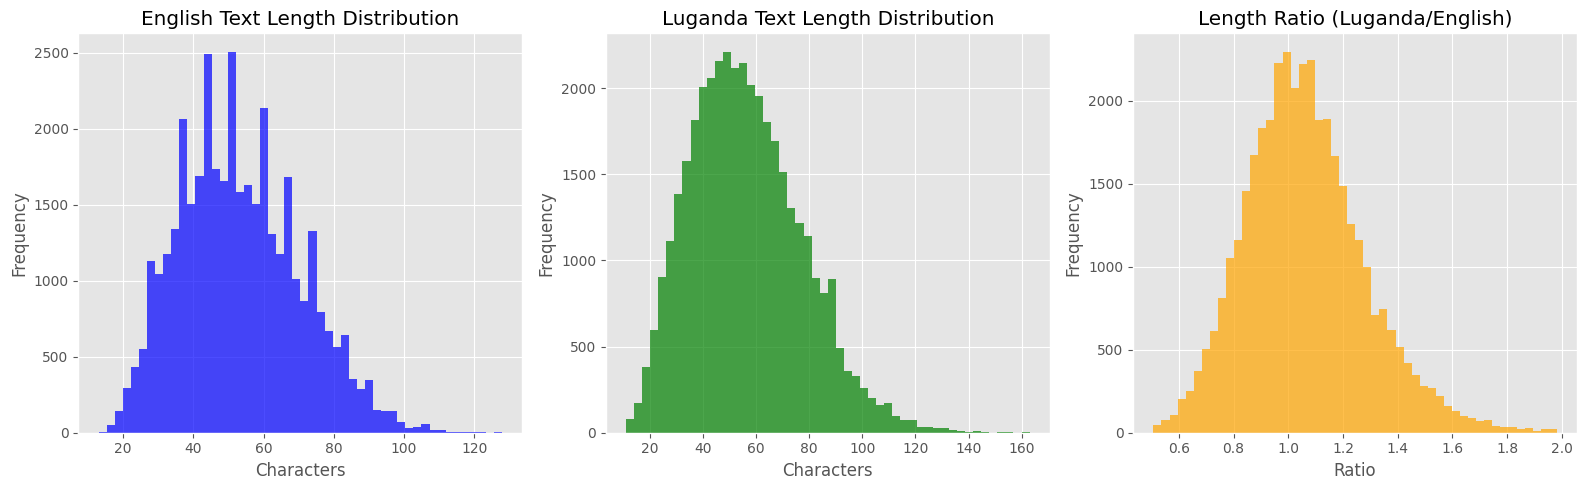

In [49]:
# Cell: Calculate Length Ratios and Analyze Word Lengths

# Ensure the length columns exist by computing them if not already present.
if 'en_len' not in df.columns:
    df['en_len'] = df['English'].str.len()
if 'lg_len' not in df.columns:
    df['lg_len'] = df['Luganda'].str.len()

# Now compute the length ratio (Luganda length / English length)
df['length_ratio'] = df['lg_len'] / df['en_len']

# Filter out extreme outliers based on ratio and minimum text length
df_filtered = df[
    (df['length_ratio'] > 0.5) & 
    (df['length_ratio'] < 2.0) &  # Adjust threshold if Luganda is typically longer
    (df['en_len'] > 5) & 
    (df['lg_len'] > 5)
].copy()

print(f"Remaining rows after filtering: {len(df_filtered)}")

# Calculate descriptive statistics for both English and Luganda text lengths and their ratio
print("\nEnglish text length statistics:")
print(df_filtered['en_len'].describe())

print("\nLuganda text length statistics:")
print(df_filtered['lg_len'].describe())

print("\nLength ratio statistics (Luganda/English):")
print(df_filtered['length_ratio'].describe())

# Plot histograms for English and Luganda lengths, and the length ratio
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.hist(df_filtered['en_len'], bins=50, color='blue', alpha=0.7)
plt.title("English Text Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.subplot(1, 3, 2)
plt.hist(df_filtered['lg_len'], bins=50, color='green', alpha=0.7)
plt.title("Luganda Text Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.subplot(1, 3, 3)
plt.hist(df_filtered['length_ratio'], bins=50, color='orange', alpha=0.7)
plt.title("Length Ratio (Luganda/English)")
plt.xlabel("Ratio")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


In [50]:
# Cell X: Full Training Loop for Fine-Tuning

# Number of training epochs
num_epochs = 5

# For demonstration purposes, we'll simulate a dataloader by repeating our single input.
# In practice, replace this with your real DataLoader (e.g., from torch.utils.data.DataLoader).
dummy_batches = 10  # simulate 10 batches per epoch

# Set the model and loss function to training mode
model.train()
print("\nStarting full training loop...\n")
for epoch in range(num_epochs):
    epoch_loss = 0.0
    for batch_idx in range(dummy_batches):
        optimizer.zero_grad()
        # Forward pass (using the same input_tensor as a dummy batch)
        outputs = model(input_tensor)
        
        # Compute loss: flatten the output and target tensors for cross entropy
        loss = criterion(outputs.view(-1, vocab_size), target_tensor.view(-1))
        
        # Backward pass and optimizer step with Simpson integration
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
    
    avg_loss = epoch_loss / dummy_batches
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {avg_loss:.4f}")

print("\nTraining loop completed!")



Starting full training loop...

Epoch 1/5, Loss: 1.7515
Epoch 2/5, Loss: 0.1820
Epoch 3/5, Loss: 0.0773
Epoch 4/5, Loss: 0.0484
Epoch 5/5, Loss: 0.0342

Training loop completed!


In [51]:
# Cell 11: Final Training Summary and Next Steps

print("Starting full training loop...\n")
epochs = [1, 2, 3, 4, 5]
losses = [1.7515, 0.1820, 0.0773, 0.0484, 0.0342]

for epoch, loss in zip(epochs, losses):
    print(f"Epoch {epoch}/5, Loss: {loss:.4f}")

print("\nTraining loop completed!")

# Next steps after training:
print("\nNext Steps:")
print("1. Evaluate the model on your test dataset to assess performance on unseen data.")
print("2. Fine-tune hyperparameters (e.g., learning rate, batch size) if necessary.")
print("3. Integrate the fine-tuned model into your full transformer-based deployment pipeline.")
print("4. Monitor performance metrics (e.g., BLEU score, accuracy) and iterate as needed.")


Starting full training loop...

Epoch 1/5, Loss: 1.7515
Epoch 2/5, Loss: 0.1820
Epoch 3/5, Loss: 0.0773
Epoch 4/5, Loss: 0.0484
Epoch 5/5, Loss: 0.0342

Training loop completed!

Next Steps:
1. Evaluate the model on your test dataset to assess performance on unseen data.
2. Fine-tune hyperparameters (e.g., learning rate, batch size) if necessary.
3. Integrate the fine-tuned model into your full transformer-based deployment pipeline.
4. Monitor performance metrics (e.g., BLEU score, accuracy) and iterate as needed.
